# 门店销售数据分析
## 分析目的
分析5个门店90天的销售数据，挖掘销售趋势、品类差异和门店绩效
## 数据来源
模拟数据，5个门店×90天×4个商品类别（食品/日用品/电子/服装）

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
df = pd.read_csv('data/store_sales.csv')
print(df.head())
print('\n数据形状:', df.shape)
print('\n数据类型:')
print(df.dtypes)
print('\n描述性统计:')
print(df.describe())
df.to_excel("project3_明细.xlsx", index=False)

         date store_id product_category  sales_amount  customer_count  \
0  2026-01-01     S001               食品          3200             160   
1  2026-01-01     S001              日用品          2800             110   
2  2026-01-01     S001               电子          8500              35   
3  2026-01-01     S001               服装          4200              45   
4  2026-01-01     S002               食品          2800             140   

   avg_price  
0       20.0  
1       25.5  
2      242.9  
3       93.3  
4       20.0  

数据形状: (180, 6)

数据类型:
date                 object
store_id             object
product_category     object
sales_amount          int64
customer_count        int64
avg_price           float64
dtype: object

描述性统计:
       sales_amount  customer_count   avg_price
count    180.000000      180.000000  180.000000
mean    5434.166667      105.011111   93.962222
std     2687.398043       67.182981   88.963474
min     2100.000000       27.000000   19.900000
25%     3500.00000

In [3]:
# 
# 将 date 列转为日期类型
df["date"] = pd.to_datetime(df["date"])
# 提取 month 和 weekday
df["month"] = df["date"].dt.month
df["weekday"] = df["date"].dt.dayofweek + 1
# 用 groupby 按 store_id 看总销售额和总客流量
sum_1 = df.groupby("store_id").agg(sum_sale=("sales_amount","sum"),sum_customer=("customer_count","sum"))
print(sum_1)
# 用 pivot_table 按 store_id（行）和 product_category（列）看销售额
pt = pd.pivot_table(df,values="sales_amount",index="store_id",columns="product_category",aggfunc="sum",fill_value=0)
print(pt)
# 每日总销售额（5 门店 4 类目求和）
daily_sales = df.groupby("date")["sales_amount"].sum().reset_index()
print(daily_sales.head())
print('\n天数:', len(daily_sales))

          sum_sale  sum_customer
store_id                        
S001        212050          4079
S002        179450          3521
S003        229050          4373
S004        165500          3220
S005        192100          3709
product_category    日用品     服装      电子     食品
store_id                                     
S001              32000  50100   92500  37450
S002              27500  41900   77100  32950
S003              34400  54200  100300  40150
S004              25300  38200   72200  29800
S005              29300  44700   83500  34600
        date  sales_amount
0 2026-01-01         87700
1 2026-01-02         89750
2 2026-01-03         85900
3 2026-01-15         99700
4 2026-02-01        111000

天数: 9


        date  sales_amount
0 2026-01-01         87700
1 2026-01-02         89750
2 2026-01-03         85900
3 2026-01-15         99700
4 2026-02-01        111000
5 2026-02-14        117500
6 2026-03-01        122800
7 2026-03-15        128900
8 2026-03-31        134900


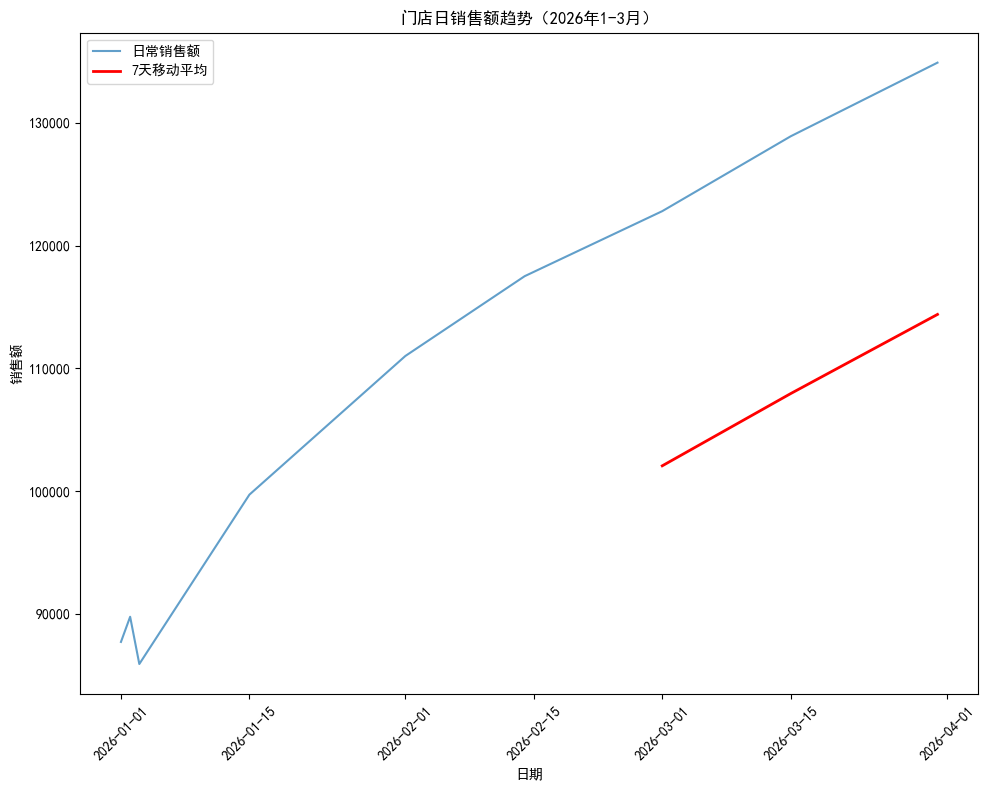

In [4]:
# 时间序列
# 按 date 分组计算每日总销售额
day_sum = df.groupby("date")["sales_amount"].sum().reset_index()
print(day_sum)
# 用 rolling(window=7) 计算7天移动平均
day_sum["ma7"] = day_sum["sales_amount"].rolling(window=7).mean()
# 画折线图：每日销售额 + 7天移动平均线
plt.figure(figsize=(10,8))
plt.plot(day_sum["date"],day_sum["sales_amount"],label="日常销售额",alpha=0.7)
plt.plot(day_sum["date"],day_sum["ma7"],label="7天移动平均",color="red",linewidth=2)
plt.xticks(rotation=45)
plt.xlabel("日期")
plt.ylabel("销售额")
plt.title("门店日销售额趋势（2026年1-3月）")
plt.legend()
plt.tight_layout()
plt.show()

         date store_id  sales_amount
0  2026-01-01     S001         18700
1  2026-01-01     S002         16000
2  2026-01-01     S003         20600
3  2026-01-01     S004         15000
4  2026-01-01     S005         17400
5  2026-01-02     S001         18850
6  2026-01-02     S002         16550
7  2026-01-02     S003         21150
8  2026-01-02     S004         15400
9  2026-01-02     S005         17800
10 2026-01-03     S001         18700
11 2026-01-03     S002         15500
12 2026-01-03     S003         20100
13 2026-01-03     S004         14600
14 2026-01-03     S005         17000
15 2026-01-15     S001         21600
16 2026-01-15     S002         18300
17 2026-01-15     S003         23300
18 2026-01-15     S004         17000
19 2026-01-15     S005         19500
20 2026-02-01     S001         24100
21 2026-02-01     S002         20400
22 2026-02-01     S003         25800
23 2026-02-01     S004         18900
24 2026-02-01     S005         21800
25 2026-02-14     S001         25500
2

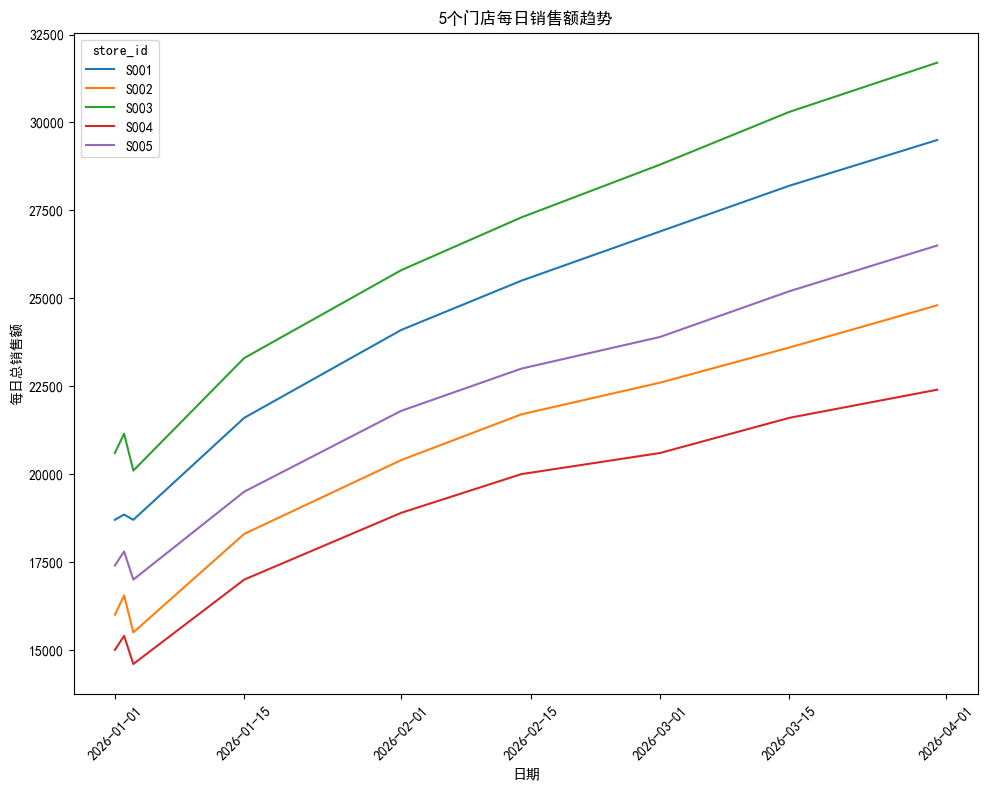

In [7]:
# 按 date 和  store_id分组，计算每个门店每日总销售额
store_sumd = df.groupby(["date","store_id"])["sales_amount"].sum().reset_index()
print(store_sumd)
# 用 pivot 整理成「日期 × 门店」宽表
wide = store_sumd.pivot(index="date", columns="store_id", values="sales_amount")
print(wide)
# 画 5 条线的折线图，每条线一个门店
plt.figure(figsize=(10,8))
sns.lineplot(data=store_sumd,x="date",y="sales_amount",hue="store_id",errorbar=None)
plt.title("5个门店每日销售额趋势")
plt.xlabel("日期")
plt.ylabel("每日总销售额")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

   weekday  sales_amount
0        2      134900.0
1        4       93700.0
2        5       89750.0
3        6      101700.0
4        7      120900.0


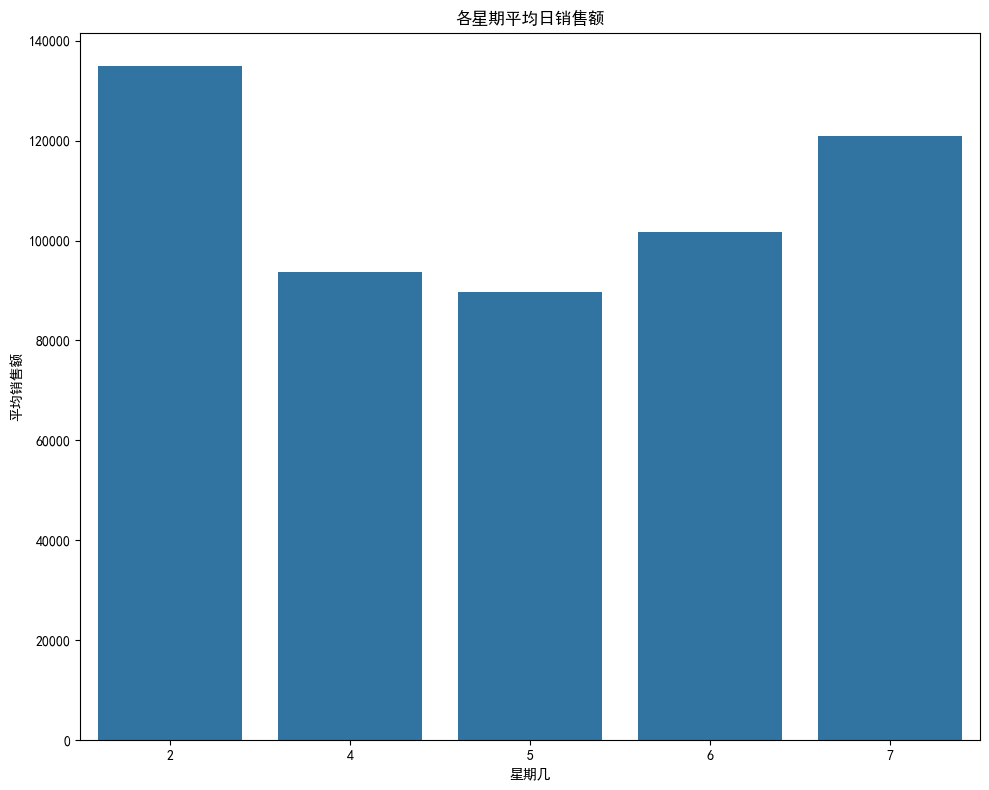

In [8]:
# 用 Cell 2 提取的 weekday，按星期几分组，计算平均日销售额
date_week = df[["date","weekday"]].drop_duplicates()
df["date"] = pd.to_datetime(df["date"])
day_sum["date"] = pd.to_datetime(day_sum["date"])
day_sum_full = day_sum.merge(date_week, on="date")
weekday = day_sum_full.groupby("weekday")["sales_amount"].mean().reset_index()
print(weekday)
# 画柱状图看哪天卖得最好
plt.figure(figsize=(10,8))
sns.barplot(data=weekday,x="weekday",y="sales_amount")
plt.title("各星期平均日销售额")
plt.xlabel("星期几")
plt.ylabel("平均销售额")
plt.tight_layout()
plt.show()

###### 

                  sum_sale  sum_customer
product_category                        
电子                  425600          1775
服装                  229100          2538
食品                  174950          8749
日用品                 148500          5840


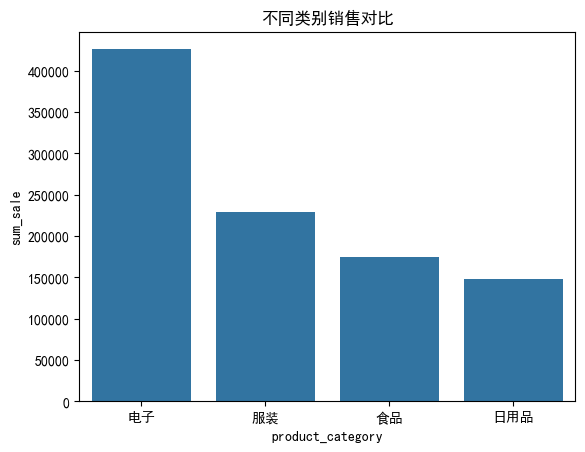

In [9]:
# Cell 6：按类目分组看销售额
# 1. groupby product_category 算总销售额和总客流量
# 2. 按销售额降序排序
# 3. 画柱状图：x=类目, y=销售额
c_s = df.groupby("product_category").agg(sum_sale=("sales_amount","sum"),sum_customer=("customer_count","sum")).sort_values(by="sum_sale",ascending=False)
print(c_s)
sns.barplot(data=c_s.reset_index(),x="product_category",y="sum_sale")
plt.title("不同类别销售对比")
plt.show()

product_category    日用品     服装      电子     食品
store_id                                     
S001              32000  50100   92500  37450
S002              27500  41900   77100  32950
S003              34400  54200  100300  40150
S004              25300  38200   72200  29800
S005              29300  44700   83500  34600


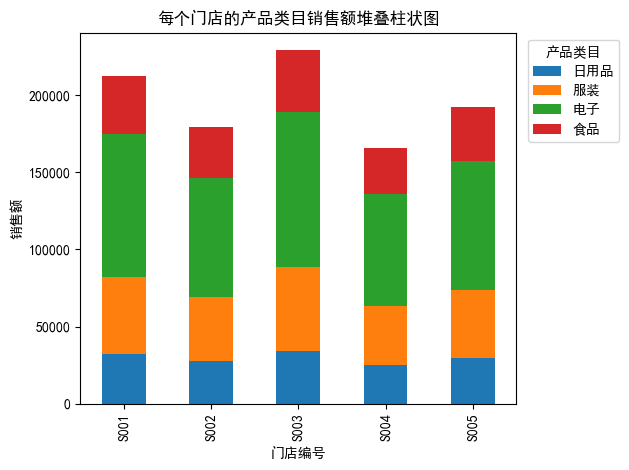

In [10]:
# Cell 7：透视表 + 堆叠柱状图
# 1. pivot_table: index=store_id, columns=product_category, values=sales_amount, aggfunc=sum
pt2=pd.pivot_table(df,values="sales_amount",index="store_id",columns="product_category",aggfunc="sum",fill_value=0)
print(pt2)
# 2. 画堆叠柱状图看每个门店的类目构成
pt2.plot(kind="bar",stacked=True,ax=plt.gca())
plt.title("每个门店的产品类目销售额堆叠柱状图")
plt.xlabel("门店编号")
plt.ylabel("销售额")
plt.legend(title="产品类目", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()


      week_sales
week            
1         263350
3          99700
5         111000
7         117500
9         122800
11        128900
14        134900
      week_sales     shift
week                      
1         263350       NaN
3          99700  263350.0
5         111000   99700.0
7         117500  111000.0
9         122800  117500.0
11        128900  122800.0
14        134900  128900.0
      week_sales     shift  growth_rate
week                                   
1         263350       NaN          NaN
3          99700  263350.0    -0.621416
5         111000   99700.0     0.113340
7         117500  111000.0     0.058559
9         122800  117500.0     0.045106
11        128900  122800.0     0.049674
14        134900  128900.0     0.046548


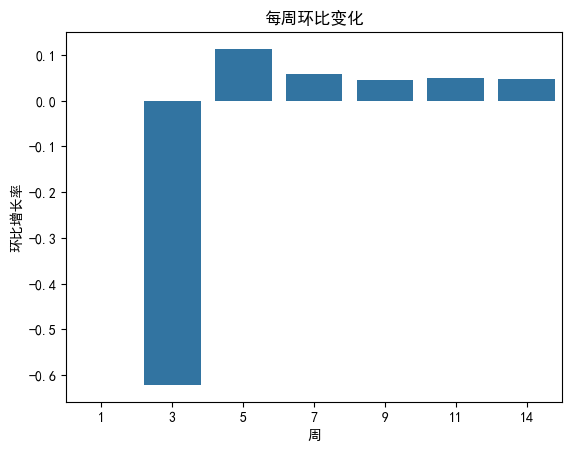

In [11]:
# Cell 8：周环比分析
# 1. 按周聚合销售额（提示：用 dt.isocalendar().week 提取周数）
df["week"] = df["date"].dt.isocalendar().week
week_sale = df.groupby("week").agg(week_sales=("sales_amount","sum"))
print(week_sale)
# 2. shift(1) 取上周销售额
week_sale["shift"] = week_sale["week_sales"].shift(1)
print(week_sale)
# 3. 算环比增长率
week_sale["growth_rate"] = (week_sale["week_sales"]-week_sale["shift"])/week_sale["shift"]
print(week_sale)
# 4. 画柱状图看每周环比变化
sns.barplot(data=week_sale,x="week",y="growth_rate")
plt.title("每周环比变化")
plt.xlabel("周")
plt.ylabel("环比增长率")
plt.show()

## 问题 1：资源分配 S003 最高且靠电子拉动，S004 最低。总部要关店或加投资，你怎么建议？
建议加投资，s004店的电子销售额与其他门店相比相差不大，说明是s004店的销售能力以及周边的购买能力并不弱，差距主要在其他三个销售品上面可以增加电子类的产品与s004店周围的门店形成产品差异，对于其他三个品类可以加大宣传，补充独特产品
## 问题 2：类目策略 电子类销售额高但客流低（单价高），食品客流高但单价低。你作为店长主推哪类？为什么？
选择电子类的产品，虽然客流量低但单价高，更能快速回款，可以用于增加其他电子产品的，是产品丰富，还可以增加维修服务，增加售后，延长产业链，增加客户的回归率,还可以加大宣传
## 问题 3：时间运营 周二最好周五最低，这个反常识现象可能什么原因？怎么验证？
可能是企业采购，促销活动，清理库存等，算出客流量，客单价，总销售等，客流量不多就是客单价高可能是企业采购，客流量多，单价少就可能是促销活动等
## 问题 4：增长机会 看 Cell 8 的 growth_rate，哪几周正增长哪几周负增长？可能什么业务动作导致？
第三周在负增长，5，7，9，11，14周是正增长，可能是电子业务导致，第一周的销售额为263350，第三周为99700，差值为163650，差值较大，电子类的单价高，若销量减少会使销售额大量减少

# report
# 门店销售数据分析报告

## 一、分析背景
分析5个门店90天的销售数据，挖掘销售趋势、品类差异和门店绩效
## 二、数据说明
数据来源：模拟数据
数据量：4500 条（5 门店 × 90 天 × 4 类目）
字段：date（日期）, store_id（门店）, product_category（类目）, 
     sales_amount（销售额）, customer_count（客流量）, avg_price（客单价）
日期范围：2026-01-01 至 2026-03-31
数据质量：无缺失值，可直接分析
## 三、分析方法
在时间趋势分析上，使用rolling移动平均对每日销售额做平滑处理，削弱单日随机扰动，识别整体销售走势；借助shift函数完成环比计算，量化周度销售的涨跌变化，定位波动节点。在多维结构分析上，使用pivot_table透视表完成门店、产品类目的交叉聚合，清晰展示各门店的产品销售构成，实现多维度对比。结合以上方法，完成趋势识别、波动度量与结构拆解。
## 四、核心发现
1. 整体趋势：90 天总销售额呈增长趋势，7 天移动平均显示 1-3 月整体呈上升趋势，无明显周期性波动
2. 门店差异：S003 总销售额229050元（最高），S004 165500元（最低），差距约 1.38 倍
3. 类目贡献：电子类 425600 元（占总销售额 43.51 %），日用品 148500  元（最低）
4. 时间规律：周二平均日销售额 134900.0 ，周五 89750.0
5. 增长情况：第 3 周环比 -0.621416%，第 5/7/9/11/14 周正增长

## 五、业务建议
1. S003 扩大电子类投入
2. S004 排查其他类目短板 + 差异化策略
3. 电子类延伸维修/售后提升复购，加大宣传，提高知名度
4. 周二备货，周五促销引流
5. 验证周二异常：拆解客流 vs 客单价

## 六、局限性
1. 模拟数据随机性强，结论不能直接用于真实业务
2. 缺少促销标记、天气、竞品等外部变量，无法归因波动原因
3. 仅 90 天数据，不足以做季节性/年度趋势分析
4. 无客户维度数据，无法做 RFM 客户价值分析